In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np


/s/chromatin/a/nobackup/Saira/anaconda3/envs/venv3/lib/python3.12/site-packages/pandas/core/arrays/masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


In [52]:
# for DNA binding factors
res_dir = "../results/final_enhancers_DNA_c1"

In [53]:
# for histone modifications
res_dir = "../results/final_enhancers_histone_c1"

### Deep Plant Results

In [2]:
deepplant_res = []
with open("../results/TF_targets_deep_plant.txt", "r") as f:
    for line in f:
        deepplant_res.append(line.strip())
deepplant_factors = [x.split("-")[0] for x in deepplant_res]

In [3]:
deepplant_res_hm = []
with open("../results/HM _targets_deepplant.txt", "r") as f:
    for line in f:
        deepplant_res_hm.append(line.strip())
deepplant_factors = [x.split("-")[0] for x in deepplant_res_hm]

### Chrombert feature importance 

In [4]:
old_dir_chrombert = "finetune_models_w1_2500bp_clustered_mtx_c1"
dir_chrombert = "finetune_models_w1_2500bp_5emb_clustered_mtx_c1"

In [12]:
## DNA binding 
chrombert_dna_df = pd.read_csv(f"../results/chrombert_finetune/{dir_chrombert}/chrombert_dna_factor_importance_rank.csv")
chrombert_hm_df = pd.read_csv(f"../results/chrombert_finetune/{dir_chrombert}/chrombert_histone_factor_importance_rank.csv")


In [13]:
chrombert_dna_df

,factors,similarity,rank,embedding_shift,factor name,factor type
0,SRX1161364,0.194858,265,0.805142,MORC1,DNA-binding protein
1,SRX5507864,0.196590,268,0.803410,GRF3,DNA-binding protein
2,SRX1161361,0.203851,275,0.796149,MORC1,DNA-binding protein
3,SRX1161368,0.221119,289,0.778881,MORC1,DNA-binding protein
4,SRR1636731,0.225936,291,0.774064,SDG8,DNA-binding protein
...,...,...,...,...,...,...
1499,SRX1412268,0.946034,2683,0.053966,EIN3,DNA-binding protein
1500,ERX011403,0.946727,2684,0.053273,SEP3,DNA-binding protein
1501,SRX1412357,0.947298,2685,0.052702,WUS1,DNA-binding protein
1502,ERX011402,0.948381,2687,0.051619,SEP3,DNA-binding protein


### IG over chrombert

In [10]:
chrombert_ig_dna_df = pd.read_csv(f"../results/chrombert_finetune/{dir_chrombert}/ig_chrombert_dna_factor_importance_rank_2.csv")
chrombert_ig_hm_df = pd.read_csv(f"../results/chrombert_finetune/{dir_chrombert}/ig_chrombert_histone_factor_importance_rank_2.csv")

In [11]:
chrombert_ig_dna_df.sort_values(by="mean_attribution", ascending=False, inplace=True)

chrombert_ig_dna_df.head(20)

,cistrome,mean_attribution,mean_abs_attribution,rank,factor type,factor name
0,SRX1412187,0.024862,0.024862,2,DNA-binding protein,GATA11
2,SRX1412185,0.019920,0.019920,5,DNA-binding protein,GATA1
3,SRX1412522,0.016642,0.016731,7,DNA-binding protein,ANAC017
4,SRX5488559,0.015576,0.015576,8,DNA-binding protein,AGL16
5,SRX8718706,0.014296,0.014423,11,DNA-binding protein,RDM15
7,SRX1161361,0.013234,0.013234,14,DNA-binding protein,MORC1
10,SRX3255812,0.012109,0.012349,17,DNA-binding protein,SYD
11,SRX1412653,0.012064,0.012064,18,DNA-binding protein,AT5G05550
8,SRX6875218,0.011546,0.012963,15,DNA-binding protein,TCX5
13,SRX5507861,0.010648,0.010648,23,DNA-binding protein,GRF1


In [9]:
chrombert_ig_dna_df.sort_values(by="mean_attribution", ascending=False, inplace=True)
chrombert_ig_dna_df.head(20)

,cistrome,mean_attribution,mean_abs_attribution,rank,factor type,factor name
0,SRX1412187,0.025010,0.025010,2,DNA-binding protein,GATA11
2,SRX1412185,0.020038,0.020038,5,DNA-binding protein,GATA1
3,SRX1412522,0.016454,0.016543,7,DNA-binding protein,ANAC017
4,SRX5488559,0.015253,0.015253,9,DNA-binding protein,AGL16
5,SRX8718706,0.014328,0.014456,10,DNA-binding protein,RDM15
7,SRX1161361,0.013092,0.013092,14,DNA-binding protein,MORC1
9,SRX3255812,0.012113,0.012354,16,DNA-binding protein,SYD
11,SRX1412653,0.011985,0.011985,19,DNA-binding protein,AT5G05550
8,SRX6875218,0.011690,0.012964,15,DNA-binding protein,TCX5
13,SRX5507861,0.010642,0.010642,23,DNA-binding protein,GRF1


### Shap values over RBF 

In [14]:
dna_dir = "5_embeddings_C1_xgb_Dna_2"
hm_dir = "5_embeddings_C1_xgb_HM_2"

# old hm and dna directories
# hm_dir = "final_enhancers_histone_c1"
# dna_dir = "final_enhancers_DNA_c1"

In [16]:
dna_dir = "5_embeddings_C1_xgb_Dna"
hm_dir = "5_embeddings_C1_xgb_HM"

shap_rbf = pd.read_csv(f"../results/{dna_dir}/rbf_svm_shap_values_rank.csv")
shap_rbf_hm = pd.read_csv(f"../results/{hm_dir}/rbf_svm_shap_values_rank.csv")

### Shap values over Tree

In [15]:
shap_tree = pd.read_csv(f"../results/{dna_dir}/tree_shap_feature_importance.csv")
shap_tree_hm = pd.read_csv(f"../results/{hm_dir}/tree_shap_feature_importance.csv")

In [20]:
shap_tree

,feature,signed_pos,signed_neg,separation,abs_infl,factor name
0,SRX3119798,1.166360,-0.684184,1.850544,0.896367,ENAP1
1,SRX1161358,0.879015,-1.067773,1.946788,1.251381,MORC1
2,SRR1636731,0.217068,-0.452017,0.669085,0.529844,SDG8
3,SRX1161364,0.132609,-0.363726,0.496335,0.383119,MORC1
4,SRX1412044,0.122833,-0.028407,0.151240,0.045549,CRF10
...,...,...,...,...,...,...
1499,SRX6460128,-0.008253,0.008567,-0.016820,0.028865,ATAF2
1500,SRX1412207,-0.008994,-0.050765,0.041771,0.054107,AT5G22990
1501,SRX215474,-0.009550,0.005392,-0.014942,0.009869,EIN3
1502,SRX2083648,-0.010508,-0.013536,0.003028,0.049498,PHYB


### Linear SVM

In [17]:
#linear_svm = pd.read_csv("../results/final_enhancers_DNA_c1/svm_linear_feature_importance.csv")
linear_svm = pd.read_csv(f"../results/{dna_dir}/linear_svm_shap_values_rank.csv")
#linear_svm_hm = pd.read_csv("../results/final_enhancers_histone_c1/svm_linear_feature_importance.csv")
linear_svm_hm = pd.read_csv(f"../results/{hm_dir}/linear_svm_shap_values_rank.csv")

In [16]:
linear_svm_hm

,feature,signed_pos,signed_neg,separation,abs_infl,factor name,factor type
0,SRX3460332,0.038772,3.500768e-04,3.842237e-02,2.579817e-03,H4K16ac,histone related
1,SRX3929423,0.034544,5.406736e-04,3.400315e-02,2.513658e-03,H3K4me3,histone related
2,ERX1047493,0.027970,3.731658e-04,2.759706e-02,1.974651e-03,H3K4me3,histone related
3,SRX9608046,0.023754,2.139039e-04,2.354049e-02,1.579807e-03,H3K4me3,histone related
4,SRR4034132,0.021873,1.794650e-04,2.169357e-02,1.438203e-03,H3K4me3,histone related
...,...,...,...,...,...,...,...
942,SRX2659864,0.000000,-1.709229e-07,1.709229e-07,1.610053e-07,H3K36me3,histone related
943,SRX2620186,0.000000,1.098127e-07,-1.098127e-07,1.034410e-07,H4ac,histone related
944,SRX2620191,0.000000,-5.773379e-08,5.773379e-08,3.159624e-07,H4ac,histone related
945,SRX2620190,0.000000,-2.148881e-07,2.148881e-07,4.567437e-07,H4ac,histone related


In [2]:
### test bg in svm 
linear_svm = pd.read_csv("../results/5_embeddings_C1_dna/linear_svm_shap_values_rank.csv")
linear_svm_2 = pd.read_csv("../results/5_embeddings_C1_dna/linear_svm_shap_values_rank_2.csv")


In [12]:
linear_svm.sort_values("signed_pos", inplace=True, ascending=False)
linear_svm.head(20)

,feature,signed_pos,signed_neg,separation,abs_infl,factor name,factor type
0,SRX1519409,0.048086,0.000555,0.047530,0.003314,PolII,DNA-binding protein
1,SRR1636731,0.040540,0.000316,0.040225,0.002672,SDG8,DNA-binding protein
2,SRX5507864,0.035419,0.000281,0.035139,0.002320,GRF3,DNA-binding protein
3,SRX159111,0.027171,0.000276,0.026895,0.001836,NRPE1,DNA-binding protein
4,SRX7573314,0.019017,0.000135,0.018882,0.001231,MED12,DNA-binding protein
5,SRX3255811,0.018208,0.000184,0.018024,0.001230,SYD,DNA-binding protein
6,DRX225508,0.016278,0.000119,0.016160,0.001056,PolII,DNA-binding protein
7,SRX5177269,0.015879,0.000102,0.015778,0.001017,S2LB,DNA-binding protein
8,SRX1161358,0.015016,0.000274,0.014743,0.001129,MORC1,DNA-binding protein
9,SRX5213637,0.014390,0.000038,0.014353,0.000870,AGO4,DNA-binding protein


In [9]:
linear_svm_2.sort_values("signed_pos", inplace=True, ascending=False)
linear_svm_2.head(20)

,feature,signed_pos,signed_neg,separation,abs_infl,factor name,factor type
0,SRR1636731,0.068300,0.000783,0.067517,0.004701,SDG8,DNA-binding protein
1,SRX1519409,0.057833,0.000701,0.057131,0.004016,PolII,DNA-binding protein
2,SRX159111,0.033917,0.000438,0.033479,0.002381,NRPE1,DNA-binding protein
3,SRX3255811,0.033182,0.000331,0.032850,0.002237,SYD,DNA-binding protein
4,SRX5507864,0.026900,0.000272,0.026627,0.001817,GRF3,DNA-binding protein
5,SRX1161358,0.020249,0.000383,0.019866,0.001536,MORC1,DNA-binding protein
6,SRX7573314,0.016506,0.000109,0.016397,0.001060,MED12,DNA-binding protein
7,SRX5177269,0.016334,0.000162,0.016172,0.001100,S2LB,DNA-binding protein
8,SRX667990,0.015361,0.000182,0.015178,0.001063,BLJ,DNA-binding protein
9,SRX1161364,0.014899,0.000310,0.014589,0.001157,MORC1,DNA-binding protein


In [18]:

path_hm = "../results/HM _targets_deepplant.txt"
path_dna = "../results/TF_targets_deep_plant.txt"
lines = [l.strip() for l in open(path_hm) if l.strip()]
    
dp_hm = pd.DataFrame({"id": [l.split("-")[-1] for l in lines],
                       "score": -np.arange(1, len(lines) + 1)})
dp_hm = dp_hm.drop_duplicates("id", keep="first")

path_dna = "../results/TF_targets_deep_plant.txt"
lines = [l.strip() for l in open(path_dna) if l.strip()]
dp_dna = pd.DataFrame({"id": [l.split("-")[-1] for l in lines],
                       "score": -np.arange(1, len(lines) + 1)})
dp_dna = dp_dna.drop_duplicates("id", keep="first")


In [24]:
shap_tree_hm

,feature,signed_pos,signed_neg,separation,abs_infl,factor name
0,SRX3119798,1.268012,-0.793530,2.061541,1.015123,ENAP1
1,SRX1161358,0.701875,-0.917260,1.619136,1.063863,MORC1
2,SRR1636731,0.224699,-0.480688,0.705386,0.552049,SDG8
3,SRX1161364,0.195253,-0.450544,0.645797,0.481689,MORC1
4,SRX5177267,0.116483,-0.035577,0.152059,0.096662,SDG2
...,...,...,...,...,...,...
1504,SRX6460127,-0.015249,0.019888,-0.035136,0.049115,ORA59
1505,SRX1412557,-0.015472,0.019941,-0.035413,0.066961,ATAF1
1506,SRX215474,-0.016855,0.016381,-0.033236,0.022649,EIN3
1507,SRX1967535,-0.021216,-0.013324,-0.007892,0.051267,NUP1


In [19]:
import itertools

import numpy as np
from matplotlib.colors import LinearSegmentedColormap, LogNorm, TwoSlopeNorm
from matplotlib.patches import Rectangle
from scipy.stats import hypergeom, spearmanr

TOP_N = 10

# (label, dataframe, id column, score column) -- reuses the frames loaded above.
# every score here is higher-is-better
METHODS = [
    ("ChromBERT ES", chrombert_hm_df,    "factors",  "embedding_shift"),
    ("ChromBERT IG",          chrombert_ig_hm_df, "cistrome", "mean_attribution"),
    ("DeepPlant",             dp_hm,                   "id",       "score"),
    ("SVM-RBF",          shap_rbf_hm,            "feature",  "signed_pos"),
    ("XGB",             shap_tree_hm,           "feature",  "signed_pos"),
    ("SVM-Linear",            linear_svm_hm,          "feature",  "signed_pos"),
]
METHODS_DNA = [
    ("ChromBERT ES", chrombert_dna_df,    "factors",  "embedding_shift"),
    ("ChromBERT IG",          chrombert_ig_dna_df, "cistrome", "mean_attribution"),
    ("DeepPlant",             dp_dna,                   "id",       "score"),
    ("SVM-RBF",          shap_rbf,            "feature",  "signed_pos"),
    ("XGB",             shap_tree,           "feature",  "signed_pos"),
    ("SVM-Linear",            linear_svm,          "feature",  "signed_pos"),
]

name_map = dict(zip(chrombert_hm_df["factors"], chrombert_hm_df["factor name"]))
name_map_dna = dict(zip(chrombert_dna_df["factors"], chrombert_dna_df["factor name"]))

print(f"{len(name_map)} cistromes -> {len(set(name_map.values()))} unique factors")

/tmp/ipykernel_2404347/3340888012.py:6: UserWarning: A NumPy version >=1.26.4 and <2.7.0 is required for this version of SciPy (detected version 1.26.3)
  from scipy.stats import hypergeom, spearmanr


947 cistromes -> 50 unique factors


---
## DeepPlant as the baseline

`TF_targets_deep_plant.txt` has no score column, but its **line order is the ranking**
— SDG8, PolII, MED12, SYD, GRF3 sit at the top, which is not alphabetical and not the
order of any other file. Confirmed quantitatively: Spearman against the line order is
**positive for all five** other methods (+0.16 to +0.29), which would not happen for an
arbitrary ordering.

So DeepPlant is a sixth ranking, and the natural framing is to treat it as the
*baseline*: sort rows by DeepPlant rank and ask how well each method reproduces it.

In [35]:
METHODS_DNA

[('ChromBERT ES',
           factors  similarity  rank  embedding_shift factor name  \
  0     SRX3119798    0.382802   263         0.617198       ENAP1   
  1     SRX1412652    0.394442   283         0.605558   AT5G05550   
  2     SRX2693425    0.405844   303         0.594156       ENAP1   
  3     SRX1412369    0.406800   306         0.593200        LBD2   
  4     SRX2910938    0.409916   312         0.590084        HD2B   
  ...          ...         ...   ...              ...         ...   
  1504  SRX1412677    0.964676  2685         0.035324      WRKY25   
  1505  SRX1412499    0.965818  2686         0.034182   AT5G47390   
  1506  SRX1412886    0.967149  2687         0.032851       WRKY7   
  1507  SRX1412680    0.967587  2688         0.032413      WRKY27   
  1508  SRX1412486    0.968672  2689         0.031328   AT1G74840   
  
                factor type  
  0     DNA-binding protein  
  1     DNA-binding protein  
  2     DNA-binding protein  
  3     DNA-binding protein  
 

In [20]:
import os

# style tokens: sequential single hue, light -> dark (not a rainbow)
BLUE = LinearSegmentedColormap.from_list(
    "seqblue", ["#f2f6fb", "#c6dbef", "#7fb0d8", "#3d7fb8", "#12518c", "#08306b"])
INK, MUTED = "#1a1a1a", "#6b6b6b"

odir = "../results/method_comparison_2"
os.makedirs(odir, exist_ok=True)

BASE = "ChromBERT ES"
TOP_N_DP = 20

def load_rankings_with_baseline(level="factor", feature_type="histone"):
    """As load_rankings, but with DeepPlant prepended as a sixth column.

    DeepPlant rank = position in the file (1 = first line). The score is negated
    so that, like every other column, higher score = more important.
    """
    if feature_type == "histone":
        methods, nmap = METHODS, name_map
    else:
        methods, nmap = METHODS_DNA, name_map_dna

    cols = {}
    for label, df, idc, sc in methods:
        print(label)
        
        d = df[[idc, sc]].copy()
        d.columns = ["id", "score"]
        if level == "factor":
            d["id"] = d["id"].map(nmap)
            d = d.dropna(subset=["id"]).groupby("id", as_index=False)["score"].max()
        cols[label] = pd.Series(d["score"].rank(ascending=False, method="min").values,
                                index=d["id"].values)
    
    return pd.DataFrame(cols).dropna(subset=[m[0] for m in methods])


rank6 = load_rankings_with_baseline("factor", "histone")
rank6_dna = load_rankings_with_baseline("factor", "dna")
print(f"{len(rank6)} factors | no DeepPlant rank for {int(rank6[BASE].isna().sum())}")
print(f"{len(rank6_dna)} DNA binding proteins | no DeepPlant rank for {int(rank6_dna[BASE].isna().sum())}")
print("\nSpearman vs DeepPlant (DNA binding proteins):")
for label, *_ in METHODS_DNA:
    print(f"  {label:24s} {spearmanr(rank6_dna[BASE], rank6_dna[label], nan_policy='omit').statistic:+.3f}")
print("\nSpearman vs DeepPlant (histone modifications):")
for label, *_ in METHODS:
    print(f"  {label:24s} {spearmanr(rank6[BASE], rank6[label], nan_policy='omit').statistic:+.3f}")

ChromBERT ES
ChromBERT IG
DeepPlant
SVM-RBF
XGB
SVM-Linear
ChromBERT ES
ChromBERT IG
DeepPlant
SVM-RBF
XGB
SVM-Linear
50 factors | no DeepPlant rank for 0
753 DNA binding proteins | no DeepPlant rank for 0

Spearman vs DeepPlant (DNA binding proteins):


  ChromBERT ES             +1.000
  ChromBERT IG             +0.391
  DeepPlant                +0.281
  SVM-RBF                  +0.297
  XGB                      +0.285
  SVM-Linear               +0.263

Spearman vs DeepPlant (histone modifications):
  ChromBERT ES             +1.000
  ChromBERT IG             +0.544
  DeepPlant                +0.562
  SVM-RBF                  +0.527
  XGB                      +0.595
  SVM-Linear               +0.711


In [21]:
rank6

,ChromBERT ES,ChromBERT IG,DeepPlant,SVM-RBF,XGB,SVM-Linear
CenH3,43.0,46.0,47.0,39.0,24.0,37.0
H2A,42.0,37.0,30.0,32.0,32.0,37.0
H2AK121ub,23.0,21.0,12.0,28.0,22.0,10.0
H2AW,45.0,45.0,46.0,37.0,36.0,37.0
H2AW6,47.0,43.0,44.0,44.0,44.0,37.0
H2AW7,49.0,47.0,45.0,26.0,36.0,33.0
H2AX,39.0,44.0,37.0,41.0,36.0,37.0
H2AZ,22.0,19.0,11.0,17.0,21.0,16.0
H2Aub,29.0,31.0,35.0,10.0,43.0,31.0
H2B,32.0,2.0,39.0,3.0,17.0,18.0


In [21]:
rank6_dna

,ChromBERT ES,ChromBERT IG,DeepPlant,SVM-RBF,XGB,SVM-Linear
3XHMGBOX1,39.0,127.0,306.0,143.0,259.0,62.0
ABF1,229.0,545.0,631.0,68.0,83.0,212.0
ABF2,646.0,508.0,239.0,314.0,435.0,231.0
ABF3,627.0,444.0,420.0,314.0,395.0,231.0
ABF4,635.0,579.0,503.0,314.0,57.0,231.0
...,...,...,...,...,...,...
bZIP52,678.0,446.0,724.0,114.0,456.0,231.0
bZIP53,725.0,413.0,324.0,314.0,399.0,231.0
bZIP68,71.0,431.0,62.0,314.0,675.0,231.0
bZIP69,214.0,104.0,216.0,314.0,714.0,231.0


In [33]:
### EZH2
ezh2 = pd.read_csv("ezh2_human.csv")
ezh2 = ezh2.rename(columns={"XGBoost": "XGB"})

In [60]:
## enhancer 
ezh2 = pd.read_csv("enhancer_human.csv")
ezh2 = ezh2.rename(columns={"XGBoost": "XGB"})

In [62]:
ezh2 = ezh2.head(12)

In [63]:
ezh2["ChromBERT-ES"] = np.arange(1,13)
ezh2

/tmp/ipykernel_1438791/1758512960.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  ezh2["ChromBERT-ES"] = np.arange(1,13)


,TF Regulator,XGB,SVM Linear,SVM RBF,ChromBERT-ES
0,JUND,4,2,9,1
1,FOSL1,13,10,18,2
2,SMAD3,17,5,15,3
3,FOS,10,19,20,4
4,SP1,6,45,64,5
5,JUN,15,80,8,6
6,TCF7L2,114,90,62,7
7,SMARCC1,623,456,640,8
8,JUNB,238,253,345,9
9,SMARCA4,162,159,98,10


In [64]:
feats = list(ezh2["TF Regulator"])
plot_methods = ["SVM RBF", "XGB", "SVM Linear"]

In [65]:
ezh2.set_index("TF Regulator", inplace=True)

In [37]:
list(feats)

['STAT3',
 'EP300',
 'E2F1',
 'FOXM1',
 'POLR3G',
 'HINFP',
 'BRCA1',
 'TP53',
 'MED1',
 'SMAD4',
 'E2F4',
 'TCF7L2']

In [66]:
methods = ezh2.columns


In [67]:
n = 20
tops = {}

for m in methods:
    tops[m] = set(ezh2[m].loc[ezh2[m] <= n].index)

In [50]:
tops

{'XGB': {'E2F1', 'EP300', 'FOXM1', 'POLR3G', 'STAT3'},
 'SVM Linear': {'EP300', 'STAT3'},
 'SVM RBF': {'EP300', 'STAT3'},
 'ChromBERT-ES': {'BRCA1',
  'E2F1',
  'E2F4',
  'EP300',
  'FOXM1',
  'HINFP',
  'MED1',
  'POLR3G',
  'SMAD4',
  'STAT3',
  'TCF7L2',
  'TP53'}}

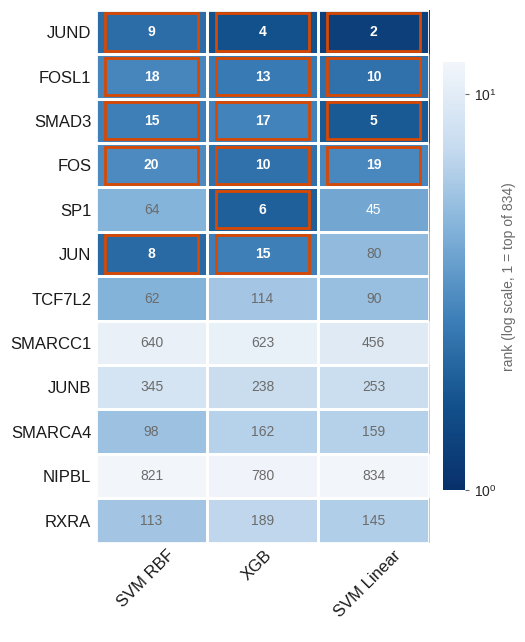

In [68]:
N = 12
plt.style.use("seaborn-v0_8-white")
mat = ezh2.loc[feats, plot_methods].values.astype(float)

vmax = ezh2[plot_methods].max().max()

fig, ax = plt.subplots(figsize=(9.2, max(5.5, 0.36 * len(feats) + 2.6)))
ax.imshow(mat, cmap=BLUE.reversed(), norm=LogNorm(vmin=1, vmax=vmax), aspect=0.4)

for i, f in enumerate(feats):
    for j, m in enumerate(plot_methods):
            v = mat[i, j]
            ax.add_patch(Rectangle((j - .5, i - .5), 1, 1, fill=False,
                                   edgecolor="white", lw=2, zorder=2))
            if np.isnan(v):                       # in our set but absent from DeepPlant
                ax.add_patch(Rectangle((j - .5, i - .5), 1, 1, facecolor="#ededed",
                                       edgecolor="white", lw=2, zorder=3))
                ax.text(j, i, "–", ha="center", va="center", color=MUTED,
                        fontsize=8, zorder=5)
                continue
            if f in tops[m]:
                ax.add_patch(Rectangle((j - .42, i - .42), .84, .84, fill=False,
                                       edgecolor="#d94801", lw=2.0, zorder=4))
            ax.text(j, i, int(v), ha="center", va="center", zorder=5, fontsize=10,
                    color="white" if v <= 50 else MUTED,
                    fontweight="bold" if f in tops[m] else "normal")

    #ax.axvline(0.5, color=INK, lw=1.6, zorder=6)   # baseline | methods being judged

    # rho = {m: spearmanr(rank_df[BASE], rank_df[m], nan_policy="omit").statistic
    #        for m in methods[1:]}
ax.set_xticks(range(len(plot_methods)))
ax.set_xticklabels([f"{m}\n"  for m in plot_methods], 
                       fontsize=12, color=INK, rotation=45) #+ r"$\rho$=" + f"{rho[m]:+.2f}"
ax.set_yticks(range(len(feats)))
ax.set_yticklabels(feats, fontsize=12, color=INK)
ax.tick_params(length=0)
for s in ax.spines.values():
        s.set_visible(False)

    # ax.set_title(f"Comparison of different feature importance methods with top-20 in {BASE}",
    #              fontsize=12.5, color=INK, loc="left", fontweight="bold", pad = 20)
    # ax.text(0, 1.0, f"{sub}\ncell = rank of {N}, darker = more important   ·   "
    #                 f"orange ring = in that method's own top {n}   ·   "
    #                ,
    #         transform=ax.transAxes, fontsize=8.2, color=MUTED, va="bottom",
    #         linespacing=1.5)
    # r"$\rho$ = Spearman vs DeepPlant, all " + f"{N} {level}s"
sm = plt.cm.ScalarMappable(cmap=BLUE.reversed(), norm=LogNorm(vmin=1, vmax=N))
cb = fig.colorbar(sm, ax=ax, fraction=.030, pad=.02)
cb.set_label(f"rank (log scale, 1 = top of {vmax})", fontsize=10, color=MUTED)
cb.ax.tick_params(labelsize=10, length=3, color=MUTED)
cb.outline.set_visible(False)
fig.savefig("enh_human.png", dpi=600, bbox_inches="tight", facecolor="white")


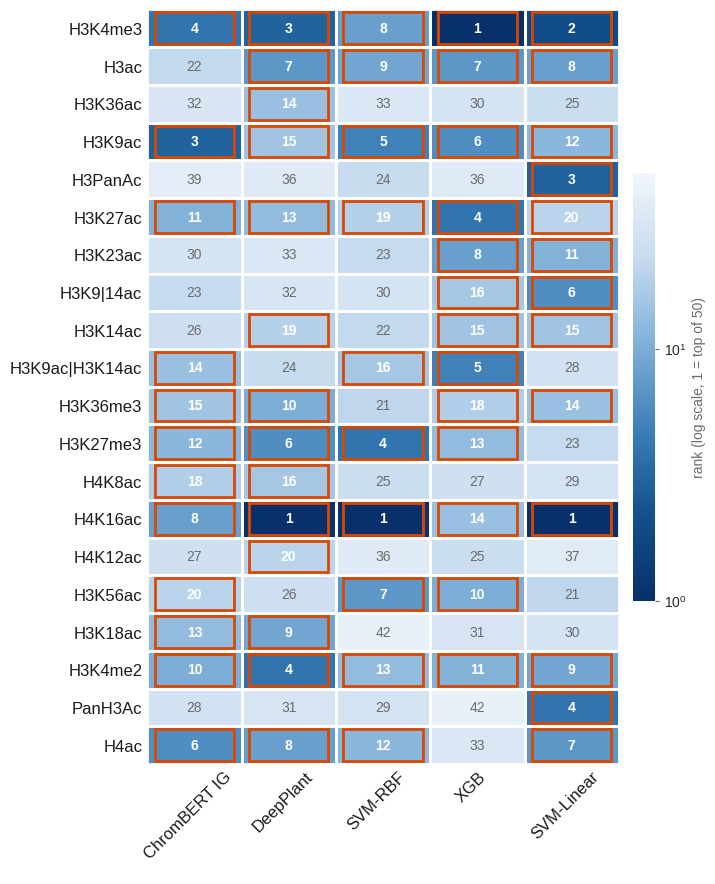

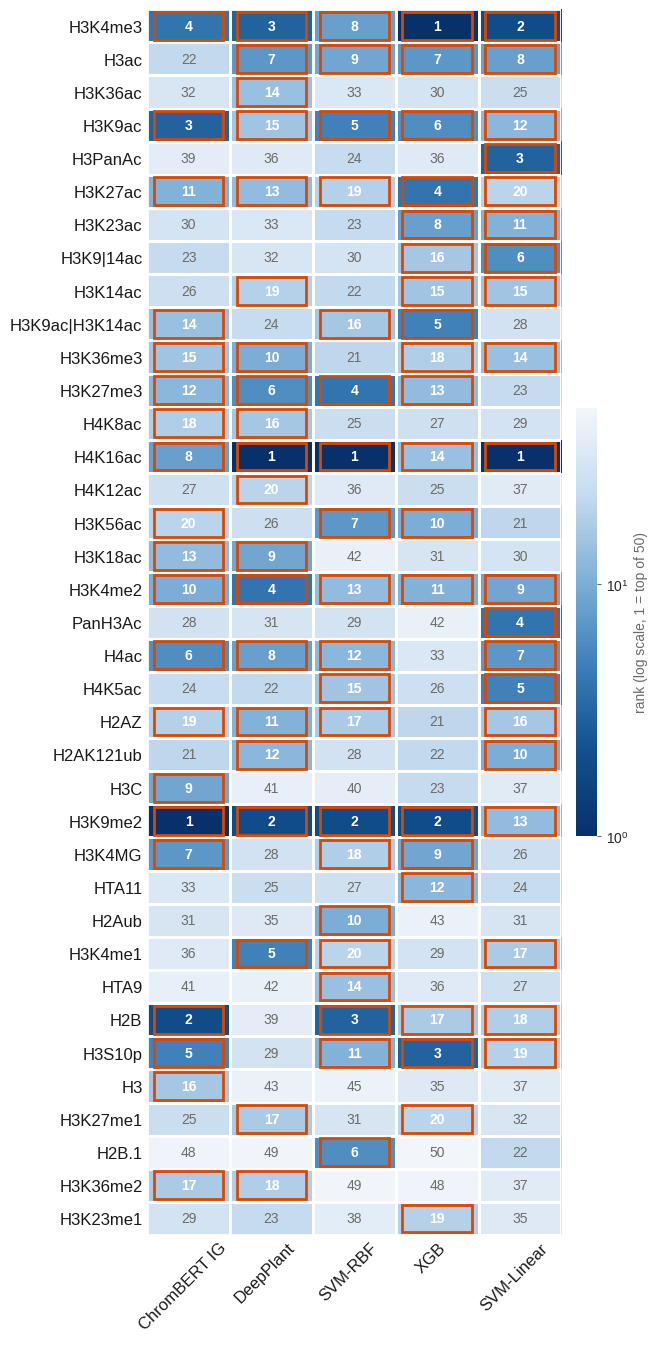

In [22]:
plt.style.use("seaborn-v0_8-white")
def plot_dp_baseline(rank_df, n=TOP_N_DP, level="factor", rows="baseline", outfile=None):
    """Rank heatmap with DeepPlant as the leftmost baseline column.

    rows="baseline" -> DeepPlant's own top-n, in DeepPlant order
    rows="union"    -> union of all six top-n lists, still sorted by DeepPlant rank
    """
    methods = list(rank_df.columns)
    N = len(rank_df)
    tops = {m: set(rank_df[m].nsmallest(n).index) for m in methods}
    plot_methods = methods[1:]
    if rows == "baseline":
        feats = list(rank_df[BASE].nsmallest(n).index)
        sub = f"rows = DeepPlant's top {n}, in DeepPlant order"
    else:
        feats = list(rank_df.loc[sorted(set().union(*tops.values()))].sort_values(BASE).index)
        sub = f"rows = union of all 6 top-{n} lists, sorted by DeepPlant rank"

    mat = rank_df.loc[feats, plot_methods].values.astype(float)

    fig, ax = plt.subplots(figsize=(9.2, max(5.5, 0.36 * len(feats) + 2.6)))
    ax.imshow(mat, cmap=BLUE.reversed(), norm=LogNorm(vmin=1, vmax=N), aspect=0.4)

    for i, f in enumerate(feats):
        for j, m in enumerate(plot_methods):
            v = mat[i, j]
            ax.add_patch(Rectangle((j - .5, i - .5), 1, 1, fill=False,
                                   edgecolor="white", lw=2, zorder=2))
            if np.isnan(v):                       # in our set but absent from DeepPlant
                ax.add_patch(Rectangle((j - .5, i - .5), 1, 1, facecolor="#ededed",
                                       edgecolor="white", lw=2, zorder=3))
                ax.text(j, i, "–", ha="center", va="center", color=MUTED,
                        fontsize=8, zorder=5)
                continue
            if f in tops[m]:
                ax.add_patch(Rectangle((j - .42, i - .42), .84, .84, fill=False,
                                       edgecolor="#d94801", lw=2.0, zorder=4))
            ax.text(j, i, int(v), ha="center", va="center", zorder=5, fontsize=10,
                    color="white" if v <= 20 else MUTED,
                    fontweight="bold" if f in tops[m] else "normal")

    #ax.axvline(0.5, color=INK, lw=1.6, zorder=6)   # baseline | methods being judged

    # rho = {m: spearmanr(rank_df[BASE], rank_df[m], nan_policy="omit").statistic
    #        for m in methods[1:]}
    ax.set_xticks(range(len(plot_methods)))
    ax.set_xticklabels([f"{m}\n"  for m in plot_methods], 
                       fontsize=12, color=INK, rotation=45) #+ r"$\rho$=" + f"{rho[m]:+.2f}"
    ax.set_yticks(range(len(feats)))
    ax.set_yticklabels(feats, fontsize=12, color=INK)
    ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)

    # ax.set_title(f"Comparison of different feature importance methods with top-20 in {BASE}",
    #              fontsize=12.5, color=INK, loc="left", fontweight="bold", pad = 20)
    # ax.text(0, 1.0, f"{sub}\ncell = rank of {N}, darker = more important   ·   "
    #                 f"orange ring = in that method's own top {n}   ·   "
    #                ,
    #         transform=ax.transAxes, fontsize=8.2, color=MUTED, va="bottom",
    #         linespacing=1.5)
    # r"$\rho$ = Spearman vs DeepPlant, all " + f"{N} {level}s"
    sm = plt.cm.ScalarMappable(cmap=BLUE.reversed(), norm=LogNorm(vmin=1, vmax=N))
    cb = fig.colorbar(sm, ax=ax, fraction=.030, pad=.02)
    cb.set_label(f"rank (log scale, 1 = top of {N})", fontsize=10, color=MUTED)
    cb.ax.tick_params(labelsize=10, length=3, color=MUTED)
    cb.outline.set_visible(False)

    if outfile:
        fig.savefig(outfile, dpi=600, bbox_inches="tight", facecolor="white")
    return fig


plot_dp_baseline(rank6, rows="baseline",
                 outfile=f"{odir}/deepplant_baseline_top{TOP_N_DP}_histone.png")
plot_dp_baseline(rank6, rows="union",
                 outfile=f"{odir}/deepplant_baseline_union_histone.png")
plt.show()

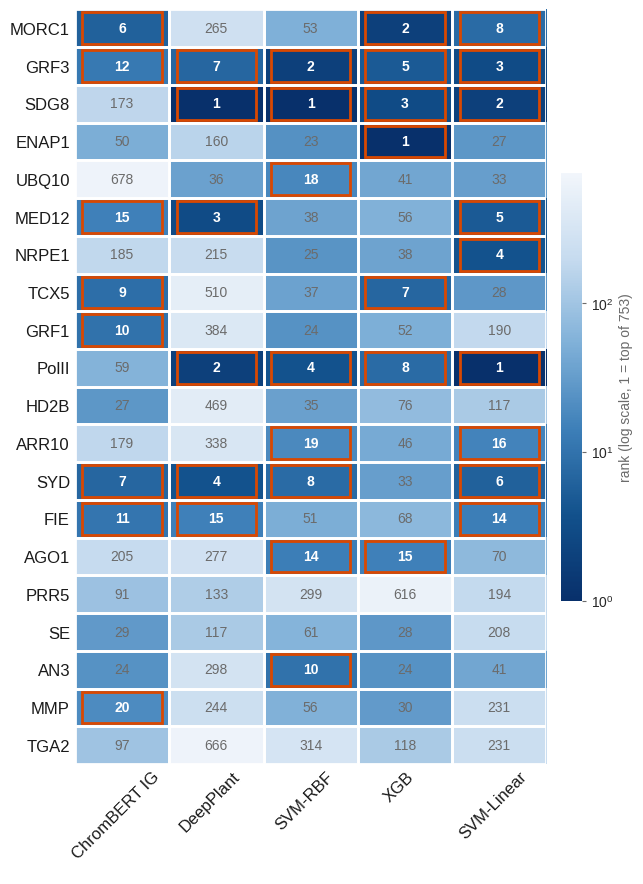

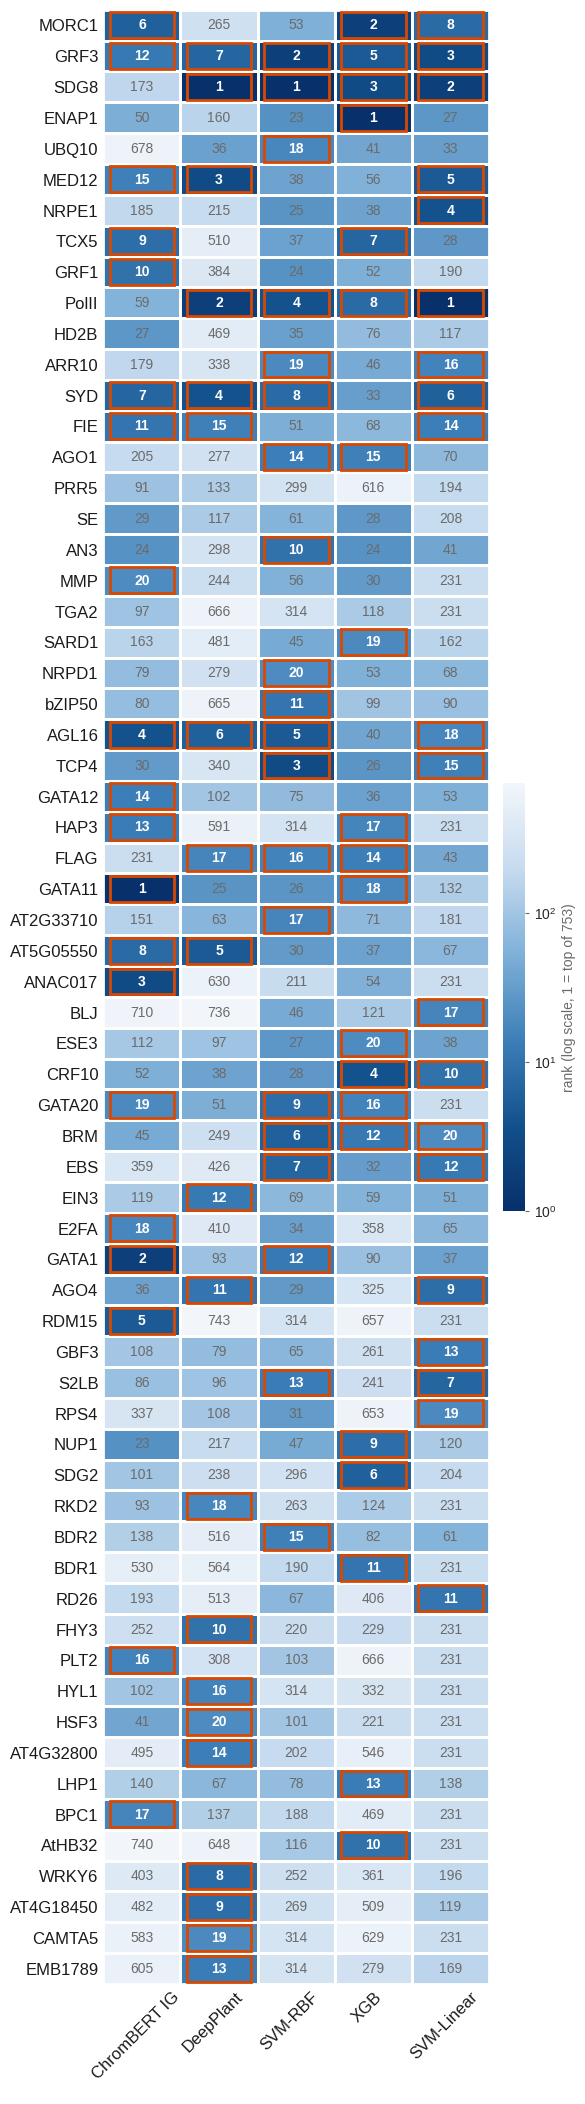

In [23]:


plot_dp_baseline(rank6_dna, rows="baseline",
                 outfile=f"{odir}/deepplant_baseline_top{TOP_N_DP}_dna.png")
plot_dp_baseline(rank6_dna, rows="union",
                 outfile=f"{odir}/deepplant_baseline_union_dna.png")
plt.show()

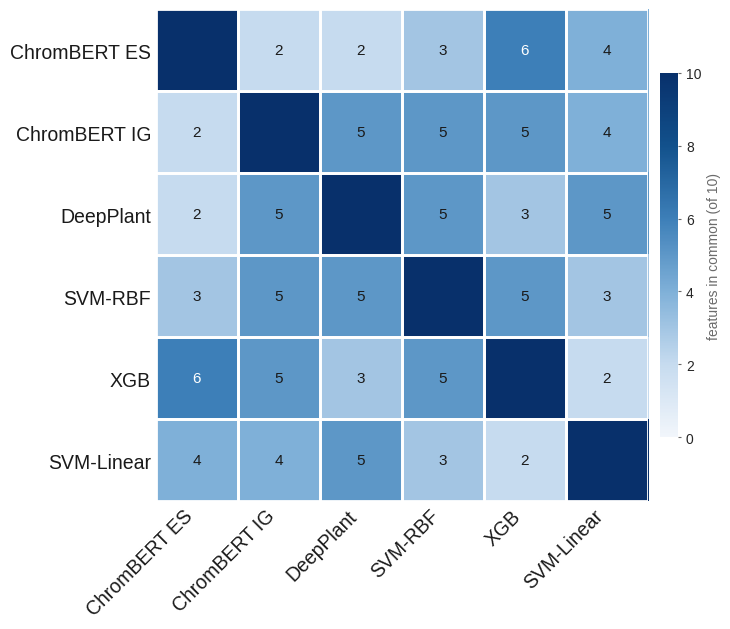

In [27]:
# All-vs-all overlap between the top-N lists, DeepPlant included.
# Cell = how many features the two methods share (not Jaccard).
TOP_N = 10
names = list(rank6.columns)                       # DeepPlant first, then the 5 methods
tops = {m: set(rank6[m].nsmallest(TOP_N).index) for m in names}
n = len(names)

overlap = np.array([[len(tops[a] & tops[b]) for b in names] for a in names])

fig, ax = plt.subplots(figsize=(7.6, 6.4))
im = ax.imshow(overlap, cmap=BLUE, vmin=0, vmax=TOP_N)

for i in range(n):
    for j in range(n):
        v = overlap[i, j]
        ax.add_patch(Rectangle((j - .5, i - .5), 1, 1, fill=False,
                               edgecolor="white", lw=2, zorder=2))
        if i == j:                                # self-overlap is TOP_N by construction
            # ax.add_patch(Rectangle((j - .5, i - .5), 1, 1, facecolor="#ededed",
            #                        edgecolor="white", lw=2, zorder=3))
            # ax.text(j, i, v, ha="center", va="center", color=MUTED,
            #         fontsize=10.5, zorder=5)
            continue
        ax.text(j, i, v, ha="center", va="center", zorder=5, fontsize=11,
                color="white" if v > TOP_N * .55 else INK)

ax.set_xticks(range(n))
ax.set_xticklabels([f"{BASE}"] + names[1:], rotation=45, ha="right",
                   fontsize=14, color=INK)
ax.set_yticks(range(n))
ax.set_yticklabels(names, fontsize=14, color=INK)
ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)

# ax.set_title(f"Features shared between methods (top {TOP_N})",
#              fontsize=12.5, color=INK, loc="left", fontweight="bold", pad=15)

cb = fig.colorbar(im, ax=ax, fraction=.030, pad=.02)
cb.set_ticks(range(0, TOP_N + 1, max(1, TOP_N // 5)))
cb.set_label(f"features in common (of {TOP_N})", fontsize=10, color=MUTED)
cb.ax.tick_params(labelsize=10, length=2, color=MUTED)
cb.outline.set_visible(False)
fig.tight_layout()
plt.savefig(f"{odir}/all_vs_all_overlap_hm_top_{TOP_N}.png", dpi=600, bbox_inches="tight", facecolor="white")
plt.show()


### Gene Expression Data 

In [ ]:
### 4 binding sites 
rf = pd.read_csv("rf_output/rf_Test_per_target_pcc.txt", sep="\t", header=None, names=["pcc"])
mlp = pd.read_csv("mlp_output_2/mlp_Test_per_target_pcc.txt", sep="\t", header=None, names=["pcc"])
xgb = pd.read_csv("../results/gene expressin/exp1_max_xgb_500_Test_per_target_pcc.txt", sep="\t", header=None, names=["pcc"])
deepplant = pd.read_csv("../../gene expression/deep_plant_results.csv", sep=",")

In [33]:
## per gene
mlp = pd.read_csv("mlp_output_3/mlp_Test_per_gene_pcc.txt", sep="\t", header=None, names=["pcc"])
#xgb = pd.read_csv("../results/gene expressin/exp1_max_xgb_500_Test_per_target_pcc.txt", sep="\t", header=None, names=["pcc"])


In [35]:
rf = pd.read_csv("rf_output5/rf_Test_per_gene_pcc.txt", sep="\t", header=None, names=["pcc"])


In [36]:
mlp["pcc"].mean(), rf["pcc"].mean()

(np.float64(0.6299098852373499), np.float64(0.6132326812728222))

In [5]:
### 5 binding sites 
rf = pd.read_csv("rf_output5/rf_Test_per_target_pcc.txt", sep="\t", header=None, names=["pcc"])
mlp = pd.read_csv("mlp_output_3/mlp_Test_per_target_pcc.txt", sep="\t", header=None, names=["pcc"])
xgb = pd.read_csv("xgb_5emb/exp1_5emb_xgb_500_Test_per_target_pcc.txt", sep="\t", header=None, names=["pcc"])
deepplant = pd.read_csv("../../gene expression/deep_plant_results.csv", sep=",")

In [6]:
deepplant

,Experiment ID,Target,Pearsonr correlation,Spearman correlation,MSE
0,989,989,0.833914,0.815410,0.825298
1,188,188,0.829165,0.808774,0.807960
2,1906,1906,0.826922,0.806414,0.790806
3,2973,2973,0.826196,0.810251,0.946351
4,1904,1904,0.825403,0.803361,0.814140
...,...,...,...,...,...
3137,122,122,NaN,NaN,0.413503
3138,123,123,NaN,NaN,0.656915
3139,125,125,NaN,NaN,0.537212
3140,2566,2566,NaN,NaN,1.075720


In [1]:
import json
chrombert_json = "/s/chromatin/c/nobackup/Saira/BERTModel/NOBERT/results/results_chrombert_gene_expression_500_log1p_mtx_5emb/test_metrics.json"

with open(chrombert_json, "r") as f:
    chrombert_data = json.load(f)



In [2]:
exp_to_pcc = {}
for exp in chrombert_data["per_gene"].items():
    name = exp[0].split("_")[-1]
    exp_to_pcc[name] = exp[1]["pearson"]

In [21]:

mlp_json = "/s/chromatin/c/nobackup/Saira/BERTModel/NOBERT/src/mlp_output_3/results/MLP_test_metrics.json"

with open(mlp_json, "r") as f:
    mlp_json = json.load(f)

gene_to_pcc = {}
for exp in mlp_json["per_gene"].items():
    name = exp[0].split("_")[-1]
    gene_to_pcc[name] = exp[1]["pearson"]

In [34]:

xgb_json = "/s/chromatin/c/nobackup/Saira/BERTModel/NOBERT/src/xgb_5emb/XGB_5emb_test_metrics.json"

with open(xgb_json, "r") as f:
    xgb_json = json.load(f)

gene_to_pcc = {}
for exp in xgb_json["per_gene"].items():
    name = exp[0].split("_")[-1]
    gene_to_pcc[name] = exp[1]["pearson"]

In [22]:
len(gene_to_pcc)

3843

In [23]:
gene_to_pcc

{'AT3G09765': 0.1543283611536026,
 'AT3G09945': 0.20903125405311584,
 'AT3G09955': 0.3918760418891907,
 'AT3G09965': 0.4240933954715729,
 'AT3G09985': 0.3715783655643463,
 'AT3G09995': -0.14022910594940186,
 'AT3G62300': 0.9196661710739136,
 'AT3G62310': 0.9530936479568481,
 'AT3G62320': 0.48736339807510376,
 'AT3G62330': 0.9083203077316284,
 'AT3G62340': 0.6520476341247559,
 'AT3G62350': 0.17627093195915222,
 'AT3G62360': 0.9378636479377747,
 'AT3G62370': 0.8527273535728455,
 'AT3G62380': 0.32239577174186707,
 'AT3G62390': 0.8007146716117859,
 'AT3G62400': 0.8596293330192566,
 'AT3G62410': 0.7617442607879639,
 'AT3G62630': 0.760610044002533,
 'AT3G62640': 0.3234809637069702,
 'AT3G62650': 0.7962433099746704,
 'AT3G62870': 0.9632070064544678,
 'AT3G62880': 0.8097620010375977,
 'AT3G62890': 0.7330595850944519,
 'AT3G62980': 0.9229588508605957,
 'AT3G62990': 0.4483892321586609,
 'AT3G63000': 0.9305691719055176,
 'AT3G63003': 0.358338862657547,
 'AT3G63006': 0.3825007379055023,
 'AT3G6301

In [20]:
import numpy as np
### coding genes 
with open("/s/chromatin/c/nobackup/Saira/BERTModel/DATA/coding_genes.txt", "r") as f:
    coding_genes = {line.strip() for line in f if line.strip()}
## non-coding genes
with open("/s/chromatin/c/nobackup/Saira/BERTModel/DATA/noncoding_genes.txt", "r") as f:
    non_coding_genes = {line.strip() for line in f if line.strip()}


In [25]:
non_coding_genes

{'AT3G08480',
 'AT3G07295',
 'AT2G08800',
 'AT1G08523',
 'AT1G07997',
 'AT1G07753',
 'AT1G08497',
 'AT5G03525',
 'AT2G08660',
 'AT1G08147',
 'AT5G02105',
 'AT1G19373',
 'AT4G05740',
 'AT4G07735',
 'AT4G08335',
 'AT5G03875',
 'AT1G08663',
 'AT1G07743',
 'AT1G05967',
 'AT1G04597',
 'AT5G09055',
 'AT4G13554',
 'AT1G05927',
 'AT3G04315',
 'AT1G09173',
 'AT3G01595',
 'AT2G09310',
 'AT3G52285',
 'AT1G69572',
 'AT3G02145',
 'AT3G08915',
 'AT1G06683',
 'AT5G07625',
 'AT1G06777',
 'AT1G48080',
 'AT5G01665',
 'AT4G05795',
 'AT5G03625',
 'AT4G06460',
 'AT5G08850',
 'AT3G09775',
 'AT1G53687',
 'AT3G60972',
 'AT3G05605',
 'AT2G06365',
 'AT5G06815',
 'AT4G07080',
 'AT3G04635',
 'AT3G05905',
 'AT1G09883',
 'AT2G09545',
 'AT2G32110',
 'AT3G21805',
 'AT5G05005',
 'AT1G33615',
 'AT3G52345',
 'AT2G07940',
 'AT4G06300',
 'AT3G08200',
 'AT5G08950',
 'AT1G20420',
 'AT1G04747',
 'AT3G06845',
 'AT3G01165',
 'AT3G07975',
 'AT2G05015',
 'AT4G06395',
 'AT5G06775',
 'AT5G06365',
 'AT3G01115',
 'AT5G45307',
 'AT4G

In [27]:
len(non_coding_genes & gene_to_pcc.keys())

527

In [28]:
len(coding_genes & gene_to_pcc.keys())

3313

In [35]:
import pandas as pd

all_coding_pcc = []
all_noncoding_pcc = []

coding_nan_count = 0
noncoding_nan_count = 0

for key, val in gene_to_pcc.items():

    if key in coding_genes:
        if pd.isna(val):
            coding_nan_count += 1
        else:
            all_coding_pcc.append(val)

    elif key in non_coding_genes:
        if pd.isna(val):
            noncoding_nan_count += 1
        else:
            all_noncoding_pcc.append(val)

In [31]:
np.mean(all_coding_pcc), np.mean(all_noncoding_pcc), coding_nan_count, coding_nan_count

(0.6876905517329599, 0.2667093923367539, 9, 9)

In [36]:
np.mean(all_coding_pcc), np.mean(all_noncoding_pcc), coding_nan_count, coding_nan_count

(0.7214193035984162, 0.2444586393403939, 9, 9)

In [37]:
df = pd.DataFrame(list(gene_to_pcc.items()), columns=["gene", "pcc"])


In [38]:
df["pcc"].mean()

0.6559473752054708

In [39]:
# convert dict to dataframe
chrombert_df = pd.DataFrame(list(exp_to_pcc.items()), columns=["experiment", "pcc"])
chrombert_df

,experiment,pcc
0,0,0.156792
1,1,0.147116
2,2,0.319475
3,3,0.401473
4,4,0.345256
...,...,...
3838,3838,0.529473
3839,3839,0.892778
3840,3840,0.431060
3841,3841,0.911737


In [40]:
chrombert_df["pcc"].mean()

np.float64(0.6060197428519238)

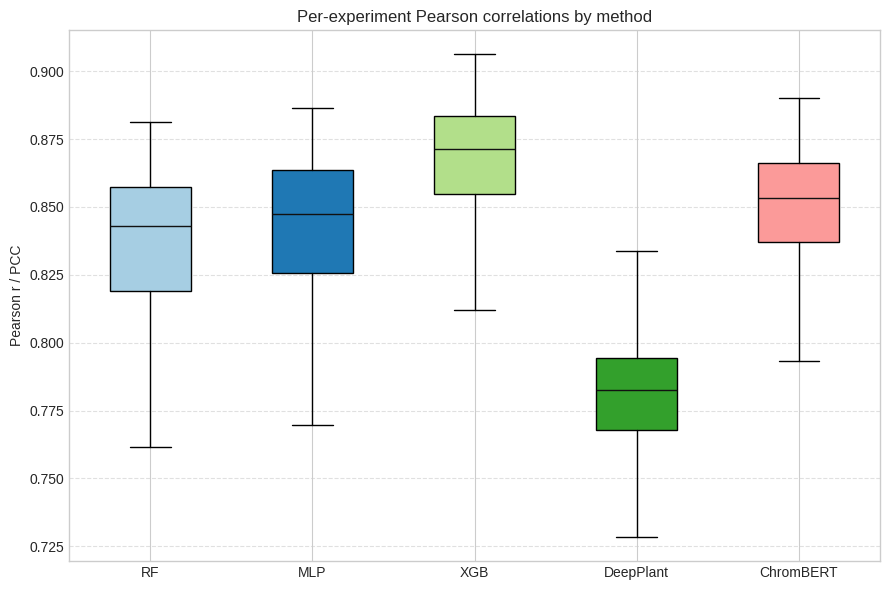

In [28]:
data = [

    rf["pcc"].values,

    mlp["pcc"].values,

    xgb["pcc"].values,

    deepplant["Pearsonr correlation"].dropna().values,

    chrombert_df["pcc"].values

]

labels = ["RF", "MLP", "XGB", "DeepPlant", "ChromBERT"]

fig, ax = plt.subplots(figsize=(9, 6))

bp = ax.boxplot(data, labels=labels, patch_artist=True, showfliers=False)

colors = ["#a6cee3", "#1f78b4", "#b2df8a", "#33a02c", "#fb9a99"]

for patch, color in zip(bp["boxes"], colors):

    patch.set_facecolor(color)

for median in bp["medians"]:

    median.set_color("#111111")

ax.set_ylabel("Pearson r / PCC")

ax.set_title("Per-experiment Pearson correlations by method")

ax.yaxis.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()

plt.show()

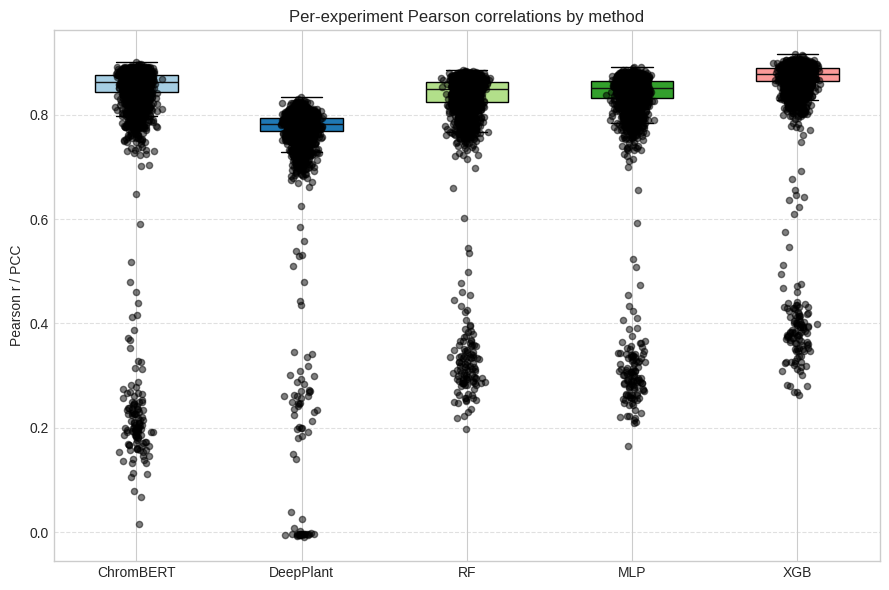

In [11]:
# boxplot comparison of per-experiment Pearson r / PCC across methods
import numpy as np
import matplotlib.pyplot as plt

data = [

    chrombert_df["pcc"].values,
    deepplant["Pearsonr correlation"].dropna().values,
    rf["pcc"].values,
    mlp["pcc"].values,
    xgb["pcc"].values,

]

labels = ["ChromBERT","DeepPlant","RF", "MLP", "XGB"]

fig, ax = plt.subplots(figsize=(9, 6))

bp = ax.boxplot(
    data,
    labels=labels,
    patch_artist=True,
    showfliers=False
)

colors = ["#a6cee3", "#1f78b4", "#b2df8a", "#33a02c", "#fb9a99"]

for patch, color in zip(bp["boxes"], colors):
    patch.set_facecolor(color)

for median in bp["medians"]:
    median.set_color("#111111")

# Add individual points
np.random.seed(42)

for i, values in enumerate(data, start=1):
    x = np.random.normal(i, 0.04, size=len(values))
    ax.scatter(
        x,
        values,
        alpha=0.5,
        s=20,
        color="black",
        zorder=3
    )

ax.set_ylabel("Pearson r / PCC")
ax.set_title("Per-experiment Pearson correlations by method")
ax.yaxis.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

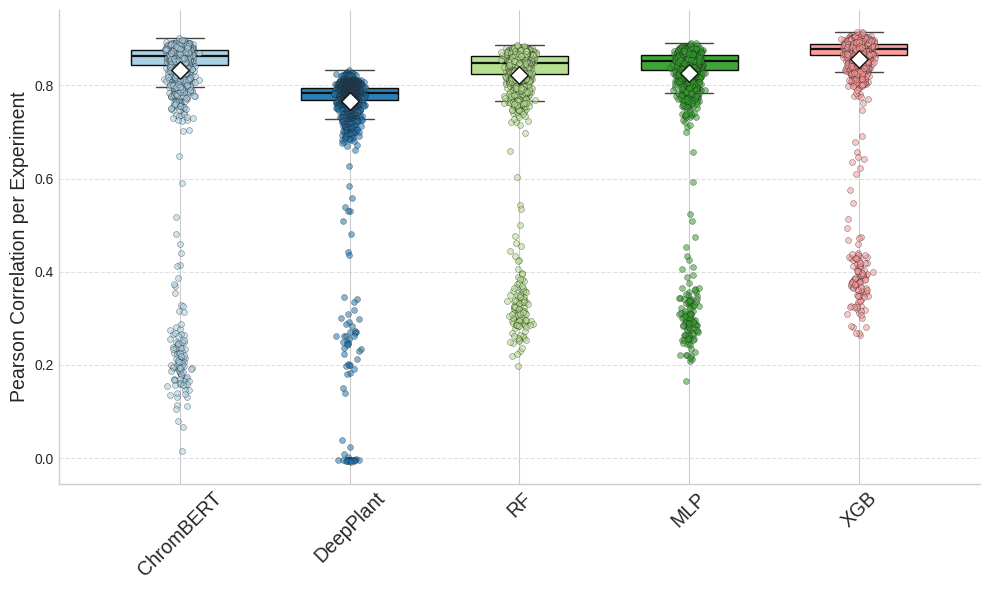

In [20]:
# improved boxplot with jittered points and mean markers (uses existing `data`, `labels`, `colors`, `odir`)
plt.style.use("seaborn-v0_8-whitegrid")
fig, ax = plt.subplots(figsize=(10, 6))
positions = np.arange(1, len(data) + 1) * 0.7

bp2 = ax.boxplot(
    data,
    positions=positions,
    widths=0.4,
    patch_artist=True,
    showfliers=False,
    medianprops=dict(color="#111111", linewidth=1.6),
    boxprops=dict(linewidth=1.0),
    whiskerprops=dict(color="#444444", linewidth=1.0),
    capprops=dict(color="#444444", linewidth=1.0),
    showmeans=True,
    meanprops=dict(marker="D", markeredgecolor="#111111", markerfacecolor="white", markersize=6),
)

# color boxes
for patch, color in zip(bp2["boxes"], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.95)

# jittered scatter points colored per-method
np.random.seed(42)
for i, vals in enumerate(data, start=1):
    # vals = np.asarray(vals)
    # vals = vals[~np.isnan(vals)]

    #q1 = np.percentile(vals, 10)
    #vals = vals[vals < q1]
    jitter_x = np.random.normal(positions[i-1], 0.02, size=len(vals))
    #jitter_x = np.ones(len(vals)) * i
    #print(i, len(vals))
    ax.scatter(jitter_x, vals, color=colors[i - 1], edgecolors="#222222",
               alpha=0.55, s=18, linewidth=0.4, zorder=3)

# overlay mean markers (larger white diamond with dark edge for contrast)
for i, vals in enumerate(data, start=1):
    mean_val = np.nanmean(vals)
    ax.scatter(positions[i-1], mean_val, marker="D", s=80, facecolor="white", edgecolor="#111111", zorder=5)

ax.set_xticks(positions)
ax.set_xticklabels(labels, fontsize=14, rotation=45)
ax.set_ylabel("Pearson Correlation per Experiment", fontsize=14)
# ax.set_xticks([0.0, 0.2, 0.4, 0.6, 0.8, 1.0])
# ax.tick_params(axis="x", labelsize=12)
ax.yaxis.grid(True, linestyle="--", alpha=0.6)

# tidy spines
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig(f"per_experiment_pcc_boxplot_with_jittered_points.png", dpi=600, bbox_inches="tight", facecolor="white")
# save to results directory if available
plt.show()

In [13]:
from scipy.stats import ttest_ind

for i in range(len(data)):
    for j in range(i + 1, len(data)):
        stat, p = ttest_ind(data[i], data[j], equal_var=False)
        print(labels[i], "vs", labels[j], "p =", p)

ChromBERT vs DeepPlant p = 3.304602629357286e-123
ChromBERT vs RF p = 0.0003074609850388736
ChromBERT vs MLP p = 0.01627602783705102
ChromBERT vs XGB p = 1.746869487757542e-18
DeepPlant vs RF p = 6.549346383832849e-112
DeepPlant vs MLP p = 4.281900769635794e-120
DeepPlant vs XGB p = 1.4482332052483662e-292
RF vs MLP p = 0.20025014635647098
RF vs XGB p = 2.580706630534845e-44
MLP vs XGB p = 3.107049039935692e-35


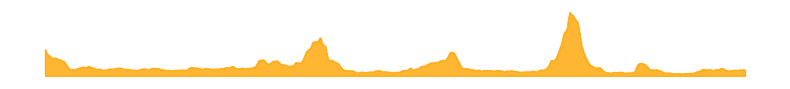

In [107]:
import pyBigWig
import matplotlib.pyplot as plt

file_path = "/s/chromatin/c/nobackup/deepplant/Data/Arabidopsis_thaliana/Bigwig/SRP318614/SRX10771698.bw"

bw = pyBigWig.open(file_path)

chrom = "Chr1"
start = 100000
end = 105000

values = bw.values(chrom, start, end)

plt.figure(figsize=(8, 1))
plt.fill_between(range(start, end), values, alpha=0.8, color="orange")
plt.axis("off")
plt.tight_layout()
plt.savefig("track_1.png", dpi = 600, bbox_inches="tight")

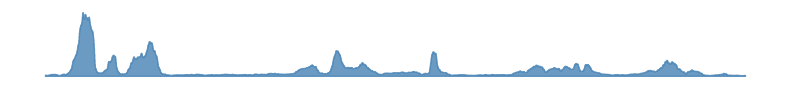

In [108]:
chrom = "Chr1"
start = 107000
end = 120000

values = bw.values(chrom, start, end)

plt.figure(figsize=(8, 1))
plt.fill_between(range(start, end), values, alpha=0.8, color="steelblue")
plt.axis("off")
plt.tight_layout()
plt.savefig("track_2.png", dpi = 600, bbox_inches="tight")

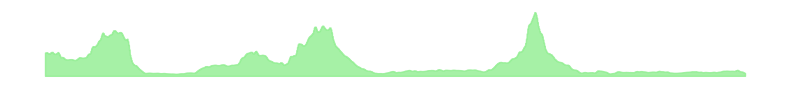

In [113]:
chrom = "Chr1"
start = 140000
end = 145000

values = bw.values(chrom, start, end)

plt.figure(figsize=(8, 1))
plt.fill_between(range(start, end), values, alpha=0.8, color="lightgreen")
plt.axis("off")
plt.tight_layout()
plt.savefig("track_3.png", dpi = 600, bbox_inches="tight")

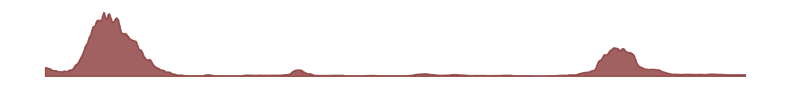

In [117]:
chrom = "Chr1"
start = 173000
end = 178000

values = bw.values(chrom, start, end)

plt.figure(figsize=(8, 1))
plt.fill_between(range(start, end), values, alpha=0.8, color="#8B3A3A")
plt.axis("off")
plt.tight_layout()
plt.savefig("track_4.png", dpi = 600, bbox_inches="tight")

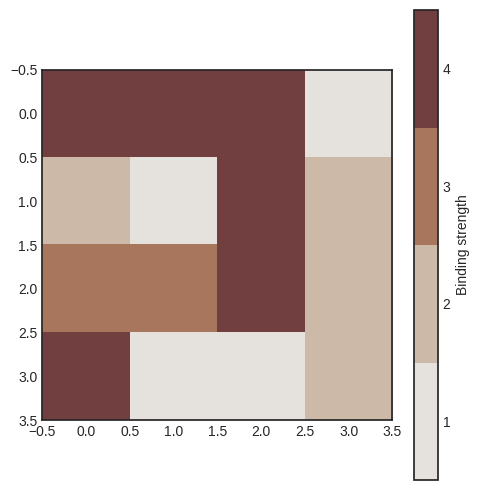

In [132]:
from matplotlib.colors import ListedColormap
import numpy as np
import matplotlib.pyplot as plt

matrix = np.random.randint(1, 5, size=(4, 4))

cmap = ListedColormap([
    "#E5E1DD",  # 1
    "#CDB9A8",  # 2
    "#A8755D",  # 3
    "#713F3F"   # 4
])

plt.figure(figsize=(5, 5))
plt.imshow(matrix, cmap=cmap, vmin=0.5, vmax=4.5)

# for i in range(4):
#     for j in range(4):
#         plt.text(j, i, matrix[i, j],
#                  ha="center", va="center",
#                  fontsize=14)

ax.set_xticks(np.arange(-0.5, 4, 1), minor=True)
ax.set_yticks(np.arange(-0.5, 4, 1), minor=True)
ax.grid(which="minor", color="#D0CBC6", linewidth=4)

# Remove minor tick marks
ax.tick_params(which="minor", bottom=False, left=False)

# plt.xticks(range(4))
# plt.yticks(range(4))
plt.colorbar(ticks=[1, 2, 3, 4], label="Binding strength")
plt.tight_layout()
plt.show()

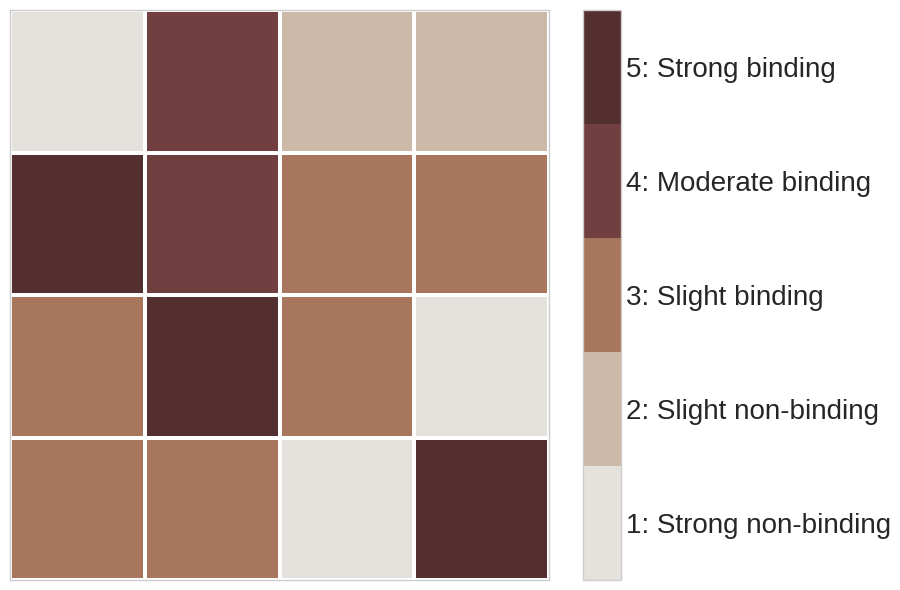

In [24]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm

matrix = np.random.randint(1, 6, size=(4, 4))

cmap = ListedColormap([
    "#E5E1DD",  # 1
    "#CDB9A8",  # 2
    "#A8755D",  # 3
    "#713F3F",    # 4
    "#542F2F"  # 5
])

fig, ax = plt.subplots(figsize=(9, 6))

norm = BoundaryNorm(
    boundaries=[0.5, 1.5, 2.5, 3.5, 4.5, 5.5],
    ncolors=cmap.N
)

im = ax.pcolormesh(
    matrix,
    cmap=cmap,
    norm = norm,
    edgecolors="#FFFFFF",  # lines between cells
    linewidth=1.5
)



ax.set_xlim(0, 4)
ax.set_ylim(4, 0)
ax.set_xticks([])
ax.set_yticks([])
cbar = plt.colorbar(im, ax=ax,aspect=15,  ticks=[1, 2, 3, 4, 5])
cbar.ax.set_yticklabels([
    "1: Strong non-binding",
    "2: Slight non-binding",
    "3: Slight binding",
    "4: Moderate binding",
    "5: Strong binding",
], fontsize=20)
plt.tight_layout()
plt.savefig("binding_strength_heatmap.png", dpi=600, bbox_inches="tight")
plt.show()